In [1]:
import os
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import matplotlib.patches as patches

import gmsh

from Source.Pre_processing.Mesh import Mesh
from Source.core import Model
from Source.Material import material
from Source.Physics.FluidFlow import ff
from Source.Physics.HeatTransfer import ht
from Source.Physics.Rheology import CrossWLF
from Source.enums import ElementType, StudyType, ProblemType, SolverType, DirectSolvers

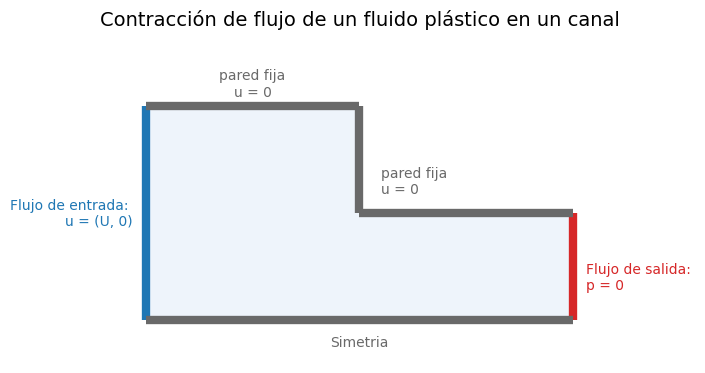

In [73]:


fig, ax = plt.subplots(figsize=(8, 6))
ax.add_patch(patches.Rectangle((0, 0), 1, 1, facecolor='#eef4fb', edgecolor='none'))
ax.add_patch(patches.Rectangle((1, 0), 1, 0.5, facecolor="#eef4fb", edgecolor='none'))
ax.plot([0, 0], [0, 1], color='tab:blue', lw=6, solid_capstyle='butt')
ax.plot([2, 2], [0, 0.5], color='tab:red', lw=6, solid_capstyle='butt')
for xs, ys in (([0, 1], [1, 1]), ([1, 1], [1, 0.5]), ([1, 2], [0.5, 0.5]), ([0, 2], [0, 0])):
    ax.plot(xs, ys, color='dimgray', lw=6, solid_capstyle='butt')

ax.text(0.5, 1.05, 'pared fija\nu = 0', ha='center', color='dimgray')
ax.text(-0.06, 0.5, 'Flujo de entrada: \nu = (U, 0)', ha='right', va='center', color='tab:blue')
ax.text(2.06, 0.2, 'Flujo de salida: \np = 0', ha='left', va='center', color='tab:red')
ax.text(1.1, 0.65, 'pared fija\nu = 0', ha='left', va='center', color='dimgray')
ax.text(1, -0.07, 'Simetria', ha='center', va='top', color='dimgray')

ax.set_xlim(-0.45, 2.45); ax.set_ylim(-0.2, 1.25); ax.set_aspect('equal'); ax.axis('off')
ax.set_title('Contracción de flujo de un fluido plástico en un canal', fontsize=14, pad=20)
plt.show()

In [150]:
H, h = 4.0e-3, 1.0e-3          # semialturas aguas arriba y aguas abajo [m]
L1, L2 = 16 * h, 16 * h        # longitudes de los tramos [m]
MU = 1000.0                    # viscosidad [Pa s]
RHO, CP, K = 750.0, 2700.0, 0.17       # fundido: densidad [kg/m3], calor específico [J/(kg K)], conductividad [W/(m K)]
Q = 1.0e-4 
T_IN = T_WALL = 230.0                  # °C


In [151]:
def contraction_mesh(lc, refine=0.15):

    """Triangulos de gmsh con la malla refinada (lc * refine) en la esquina reentrante (0, h)."""

    gmsh.initialize()
    gmsh.option.setNumber("General.Terminal", 0)
    try:
        gmsh.model.add('contraction')
        geo = gmsh.model.geo
        pts = [(-L1, 0, lc), (L2, 0, lc), (L2, h, lc), (0, h, lc * refine), (0, H, lc), (-L1, H, lc)]
        p = [geo.addPoint(x, y, 0, size) for x, y, size in pts]
        lines = [geo.addLine(p[i], p[(i + 1) % len(p)]) for i in range(len(p))]
        geo.addPlaneSurface([geo.addCurveLoop(lines)])
        geo.synchronize()
        gmsh.model.addPhysicalGroup(1, [lines[0]], name='axis')
        gmsh.model.addPhysicalGroup(1, [lines[1]], name='outlet')
        gmsh.model.addPhysicalGroup(1, [lines[2], lines[3], lines[4]], name='walls')
        gmsh.model.addPhysicalGroup(1, [lines[5]], name='inlet')
        gmsh.model.mesh.generate(2)
        return Mesh.from_gmsh_model()
    finally:
        gmsh.finalize()


In [152]:
melt = CrossWLF(n=0.28, tau_star=2.5e4, D1=5.0e13, D2=263.15, A1=30.0, A2=51.6)
mu0_230 = float(melt.zero_shear(T_IN))



In [153]:
mesh = contraction_mesh(lc=h/8, refine=0.15)
model = Model(
    name = 'extrusion_plastico',
    dim = 2,
    mesh = mesh,
    mat = material('PP', miu = mu0_230, rho = RHO, Cp = CP, k = K),
    psc = [ff, ht]
)

fluid, heat = model.physics.fluid, model.physics.heat


U_in = 1.5 * Q / H                                     # velocidad maxima del perfil de entrada
fluid.addBC_OutletEdges(mesh.boundary_edges('outlet'), 0.0)
fluid.addBC_SymmetryEdges(mesh.boundary_edges('axis'))
fluid.addBC_VelocityEdges(mesh.boundary_edges('inlet'), lambda x, y: (U_in * (1 - (y / H) ** 2), 0.0))
fluid.addBC_NoSlipEdges(mesh.boundary_edges('walls'))

heat.addBC_TemperatureEdges(mesh.boundary_edges('inlet'), T_IN)
heat.addBC_TemperatureEdges(mesh.boundary_edges('walls'), T_WALL)

model.physics.setVelocity('u')
model.physics.setStabilization('SUPG')                  # Péclet alto: el fundido conduce poco el calor
model.physics.initField('T', T_IN)

model.physics.setViscosityLaw(melt)

model.solverConfiguration(Study=StudyType.steady_state, Type=ProblemType.nonlinear, Method=SolverType.direct,
                            Solver=DirectSolvers.PARDISO)

start = time.perf_counter()
model.solve()

2026-10-31 10:52:22 - INFO - ------- Starting simulation -------
2026-10-31 10:52:22 - INFO - Model: extrusion_plastico
2026-10-31 10:52:22 - INFO - Dimension: 2D
2026-10-31 10:52:22 - INFO - Nodes: 8686
2026-10-31 10:52:22 - INFO - Elements: 16606
2026-10-31 10:52:22 - INFO - Physics: Creeping flow (Stokes), CrossWLF viscosity + Heat transfer
2026-10-31 10:52:22 - INFO - ------- Solver configuration -------
2026-10-31 10:52:22 - INFO - Study: Steady state
2026-10-31 10:52:22 - INFO - Type: Nonlinear
2026-10-31 10:52:22 - INFO - Method: Direct
2026-10-31 10:52:22 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-10-31 10:52:22 - INFO - ------- Starting Newton-Raphson nonlinear solver -------
2026-10-31 10:52:22 - INFO - Relative tolerance: 1.0e-10, Absolute tolerance: 1.0e-10, Max Number of Iterations: 200
2026-10-31 10:52:22 - INFO - -----------------------------------------------------------
2026-10-31 10:52:22 - INFO - |  Iter  |  ||R|| scaled   |  ||R||/||R0||   | Alpha

In [154]:
def inlet_pressure(model):
    nodes = np.unique(np.ravel(mesh.boundary_edges('inlet')))
    return model.sol['p'][nodes].mean()

In [155]:
isothermal = dict(u=model.sol['u'].copy(), p=model.sol['p'].copy(), T=model.sol['T'].copy(), dp=inlet_pressure(model),
                  mu=model.sol['viscosity'].copy(), rate=model.sol['shear_rate'].copy())
print(f"Cross-WLF isotérmico: caída de presión {isothermal['dp'] / 1e5:.3f} bar, "
      f"{model.newton_iterations} iteraciones ({time.perf_counter() - start:.1f} s)")

Cross-WLF isotérmico: caída de presión 8.918 bar, 6 iteraciones (13.2 s)


In [156]:
xy = np.array([node.coor for node in mesh.NL])

In [157]:
def bulk_temperature(model, x):

    """Temperatura de mezcla (ponderada con el caudal) en la sección x: integral(u T dy) / integral(u dy)."""

    column = np.abs(xy[:, 0] - x) < 1e-12
    order = np.argsort(xy[column, 1])
    y, u, T = xy[column, 1][order], model.sol['u'][column, 0][order], model.sol['T'][column][order]
    return np.trapezoid(u * T, y) / np.trapezoid(u, y)

In [158]:
fluid.setViscousHeating(True)
start = time.perf_counter()
model.solve()

2026-10-31 10:52:45 - INFO - ------- Starting simulation -------
2026-10-31 10:52:45 - INFO - Model: extrusion_plastico
2026-10-31 10:52:45 - INFO - Dimension: 2D
2026-10-31 10:52:45 - INFO - Nodes: 8686
2026-10-31 10:52:45 - INFO - Elements: 16606
2026-10-31 10:52:45 - INFO - Physics: Creeping flow (Stokes), CrossWLF viscosity, viscous heating + Heat transfer
2026-10-31 10:52:45 - INFO - ------- Solver configuration -------
2026-10-31 10:52:45 - INFO - Study: Steady state
2026-10-31 10:52:45 - INFO - Type: Nonlinear
2026-10-31 10:52:45 - INFO - Method: Direct
2026-10-31 10:52:45 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-10-31 10:52:45 - INFO - ------- Starting Newton-Raphson nonlinear solver -------
2026-10-31 10:52:45 - INFO - Relative tolerance: 1.0e-10, Absolute tolerance: 1.0e-10, Max Number of Iterations: 200
2026-10-31 10:52:45 - INFO - -----------------------------------------------------------
2026-10-31 10:52:45 - INFO - |  Iter  |  ||R|| scaled   |  ||R||

In [159]:
thermal = dict(u=model.sol['u'].copy(), p=model.sol['p'].copy(), T=model.sol['T'].copy(), dp=inlet_pressure(model),
               mu=model.sol['viscosity'].copy(), rate=model.sol['shear_rate'].copy())
q_in, q_out = -fluid.flowRate(mesh.boundary_edges('inlet')), fluid.flowRate(mesh.boundary_edges('outlet'))

In [160]:
print(f"Con calentamiento viscoso: caída de presión {thermal['dp'] / 1e5:.3f} bar, T máx {thermal['T'].max():.2f} °C, "
      f"{model.newton_iterations} iteraciones ({time.perf_counter() - start:.1f} s)")
print(f"Caudal: entrada {q_in:.6e}, salida {q_out:.6e} m2/s (diferencia {abs(q_in - q_out):.1e})")
print(f"Balance de energía: aumento adiabático dP/(rho Cp) = {thermal['dp'] / (RHO * CP):.3f} K; aumento de la temperatura "
      f"de mezcla a la salida = {bulk_temperature(model, L2) - T_IN:.3f} K (el resto sale por las paredes a {T_WALL:.0f} °C)")


Con calentamiento viscoso: caída de presión 8.893 bar, T máx 230.94 °C, 3 iteraciones (7.2 s)
Caudal: entrada 9.997559e-05, salida 9.997559e-05 m2/s (diferencia 5.4e-20)
Balance de energía: aumento adiabático dP/(rho Cp) = 0.439 K; aumento de la temperatura de mezcla a la salida = 0.275 K (el resto sale por las paredes a 230 °C)


In [161]:
triang = mtri.Triangulation(xy[:, 0] * 1e3, xy[:, 1] * 1e3, [e.getNodesId() for e in mesh.EL])


Text(0.5, 1.0, 'Temperatura por disipación viscosa (Q nominal)')

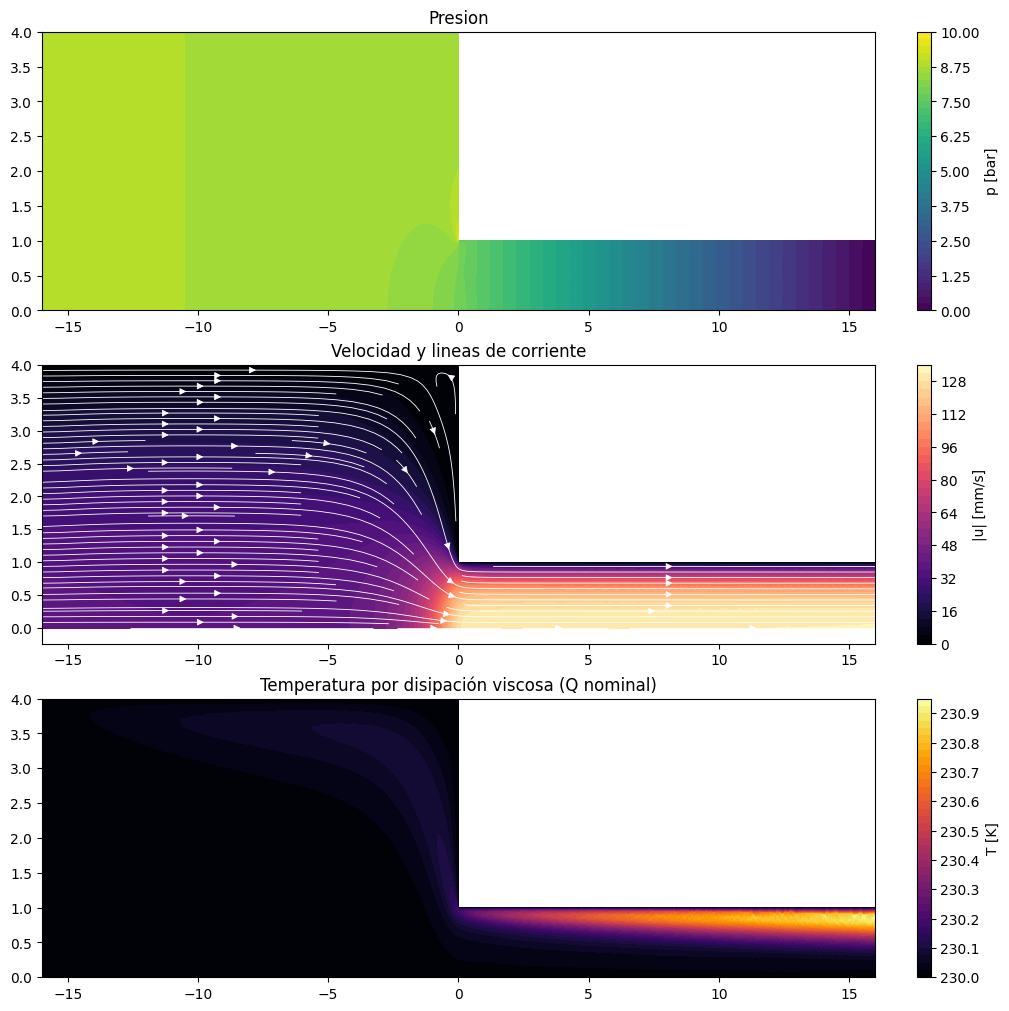

In [162]:
u = model.sol['u']

fig, axes = plt.subplots(3, 1, figsize=(10, 10), constrained_layout=True)

cs = axes[0].tricontourf(triang, model.sol['p'] / 1e5, levels=40, cmap='viridis')
fig.colorbar(cs, ax=axes[0], label='p [bar]')
axes[0].set_title('Presion')

speed = np.linalg.norm(u, axis=1)
cs = axes[1].tricontourf(triang, speed * 1e3, levels=40, cmap='magma')
fig.colorbar(cs, ax=axes[1], label='|u| [mm/s]')
gx, gy = np.meshgrid(np.linspace(-L1, L2, 400) * 1e3, np.linspace(0, H, 120) * 1e3)
ux = mtri.LinearTriInterpolator(triang, u[:, 0])(gx, gy)
uy = mtri.LinearTriInterpolator(triang, u[:, 1])(gx, gy)
axes[1].streamplot(gx, gy, ux, uy, color='w', density=1.6, linewidth=0.6)
axes[1].set_title('Velocidad y lineas de corriente')

cs = axes[2].tricontourf(triang, model.sol['T'], levels=40, cmap='inferno')
fig.colorbar(cs, ax=axes[2], label='T [K]')
axes[2].set_title('Temperatura por disipación viscosa (Q nominal)')

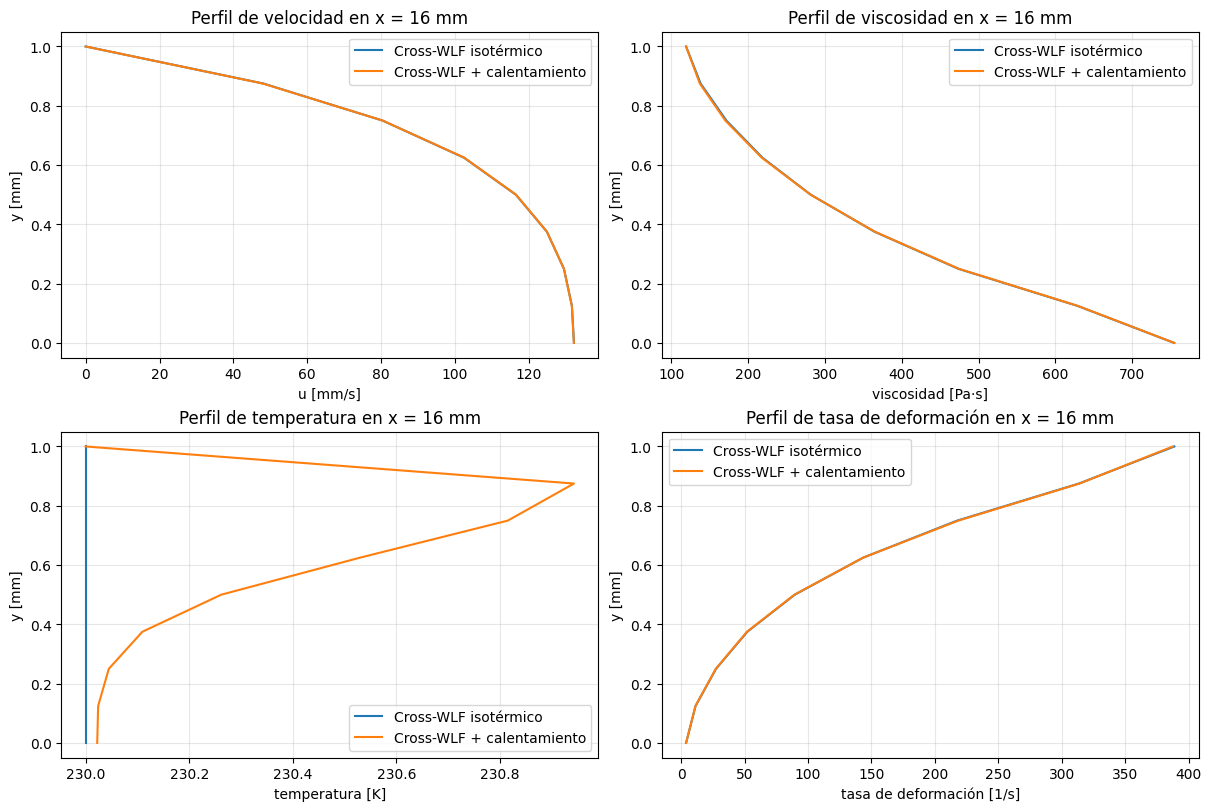

In [164]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)

column = np.abs(xy[:, 0] - L2) < 1e-12
order = np.argsort(xy[column, 1])
y_mm  = xy[column, 1][order] * 1e3

ax = axes[0, 0]
for data, label in ((isothermal, 'Cross-WLF isotérmico'), (thermal, 'Cross-WLF + calentamiento')):
    ax.plot(data['u'][column, 0][order] * 1e3, y_mm, label=label)
ax.set_xlabel('u [mm/s]'); ax.set_ylabel('y [mm]'); ax.legend(); ax.set_title('Perfil de velocidad en x = 16 mm')
ax.grid(True, alpha=0.3)

ax = axes[0, 1]
for data, label in ((isothermal, 'Cross-WLF isotérmico'), (thermal, 'Cross-WLF + calentamiento')):
    ax.plot(data['mu'][column][order], y_mm, label=label)
ax.set_xlabel('viscosidad [Pa·s]'); ax.set_ylabel('y [mm]'); ax.legend(); ax.set_title('Perfil de viscosidad en x = 16 mm')
ax.grid(True, alpha=0.3)

ax = axes[1, 0]
for data, label in ((isothermal, 'Cross-WLF isotérmico'), (thermal, 'Cross-WLF + calentamiento')):
    ax.plot(data['T'][column][order], y_mm, label=label)
ax.set_xlabel('temperatura [K]'); ax.set_ylabel('y [mm]'); ax.legend(); ax.set_title('Perfil de temperatura en x = 16 mm')
ax.grid(True, alpha=0.3)

ax = axes[1, 1]
for data, label in ((isothermal, 'Cross-WLF isotérmico'), (thermal, 'Cross-WLF + calentamiento')):
    ax.plot(data['rate'][column][order], y_mm, label=label)
ax.set_xlabel('tasa de deformación [1/s]'); ax.set_ylabel('y [mm]'); ax.legend(); ax.set_title('Perfil de tasa de deformación en x = 16 mm')
ax.grid(True, alpha=0.3)


In [163]:
isothermal

{'u': array([[ 3.75000000e-02,  0.00000000e+00],
        [ 1.32253948e-01,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00],
        ...,
        [ 5.25159548e-03, -9.46463351e-03],
        [ 6.27227571e-02, -1.47796864e-02],
        [ 1.30353579e-01, -8.75975883e-06]], shape=(8686, 2)),
 'p': array([894393.58308218,   1204.98822782,   2778.61042309, ...,
        869995.50669679, 840531.92400658, 602591.34644851], shape=(8686,)),
 'T': array([230., 230., 230., ..., 230., 230., 230.], shape=(8686,)),
 'dp': np.float64(891771.7691628926),
 'mu': array([914.70462708, 754.5227366 , 119.27891547, ..., 403.92225851,
        344.03794174, 562.98933084], shape=(8686,)),
 'rate': array([2.43339654e-01, 3.93880629e+00, 3.88812510e+02, ...,
        3.98110455e+01, 5.74692854e+01, 1.58436541e+01], shape=(8686,))}

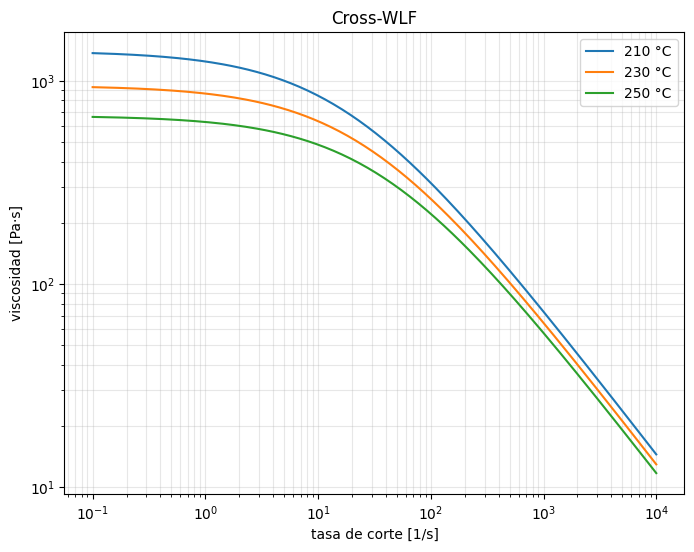

In [165]:
gamma = np.logspace(-1, 4, 200)

fig, ax = plt.subplots(figsize=(8, 6))

for T in (210.0, 230.0, 250.0):
    ax.loglog(gamma, melt.viscosity(gamma, T), label=f'{T:.0f} °C')
ax.set_xlabel('tasa de corte [1/s]'); ax.set_ylabel('viscosidad [Pa·s]'); ax.legend(); ax.set_title('Cross-WLF')
ax.grid(True, which='both', alpha=0.3)